In [4]:
import pandas as pd
import numpy as np

Pneumonia_data=r"C:\Users\Tariq\Desktop\Pneumonia\pneumonia_dataset.xlsx"
df=pd.read_excel(Pneumonia_data)
df.head(60)

#removing duplicate rows
df=df.drop_duplicates()



#Droping columns with more than 80% null values
df=df.drop(columns=['Xray', 'WBC_count'])

df=df.fillna('none')

#replacing unidentified terms with null
df=df.replace('-',np.nan)


#Standardizing string cols
cols=['Gender','Cough','Fever','Shortness_of_breath','Chest_pain','Fatigue','Confusion','Crackles','Sputum_color','Diagnosis']

for col in cols:
   df[col]= df[col].str.lower().str.strip()

#filling missing values
miss_cols=['Cough','Fever','Shortness_of_breath','Chest_pain','Fatigue','Confusion','Sputum_color']

for col in miss_cols:
    df[col]=df[col].fillna('unknown')

#Mapping
df['Diagnosis'] = df['Diagnosis'].map({'yes': 1, 'no': 0})


# Encode features
cols_cat=['Gender','Cough','Fever','Shortness_of_breath','Chest_pain','Fatigue','Confusion','Crackles','Sputum_color']
df = pd.get_dummies(df, columns=cols_cat)


#fill null values in the oxygen column
median_val=df['Oxygen_saturation'].median()
df['Oxygen_saturation']=df['Oxygen_saturation'].fillna(median_val)


C:\Users\Tariq\AppData\Local\Temp\ipykernel_15788\3943208820.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df=df.replace('-',np.nan)


In [5]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import ( mean_absolute_error,accuracy_score, precision_score,
                             recall_score, classification_report)


from sklearn.model_selection import train_test_split
import joblib

X=df.drop(columns=['PatientID','Diagnosis'])
y = df['Diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0
)
train_columns = X_train.columns

Pneumonia_model=RandomForestClassifier(
    n_estimators=70,   
    max_depth=3,         
    min_samples_split=8,
    min_samples_leaf=3,
  
    random_state=0
)
Pneumonia_model.fit(X_train,y_train)

prediction=Pneumonia_model.predict(X_test)
prob = Pneumonia_model.predict_proba(X_test)[:, 1]

print(prediction)
print(prob)

err=mean_absolute_error(prediction,y_test)
print(err)

accuracy  = accuracy_score(y_test,prediction)
print(f"\nAccuracy : {accuracy*100:.2f}%")


train_acc = Pneumonia_model.score(X_train, y_train)
test_acc  = Pneumonia_model.score(X_test, y_test)

print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Testing Accuracy:  {test_acc*100:.2f}%")

#importances = pd.Series(Pneumonia_model.feature_importances_, index=X.columns)
#print(importances.sort_values(ascending=False).head(10))

precision = precision_score(y_test, prediction)
recall    = recall_score(y_test, prediction)


print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")

"""print("\nDetailed Report:")
print(classification_report(y_test, prediction, target_names=['No Pneumonia', 'Pneumonia']))"""


joblib.dump(train_columns, "columns.pkl")
joblib.dump(Pneumonia_model, "Pneumonia_model.pkl")

0.028169014084507043

Accuracy : 97.18%
Training Accuracy: 97.01%
Testing Accuracy:  97.18%
Precision: 100.00%
Recall   : 94.94%

Detailed Report:
              precision    recall  f1-score   support

No Pneumonia       0.94      1.00      0.97        63
   Pneumonia       1.00      0.95      0.97        79

    accuracy                           0.97       142
   macro avg       0.97      0.97      0.97       142
weighted avg       0.97      0.97      0.97       142



['Pneumonia_model.pkl']

In [7]:
df.head()

,PatientID,Age,Oxygen_saturation,Temperature,Diagnosis,Gender_f,Gender_m,Cough_bloody,Cough_dry,Cough_none,...,Confusion_no,Confusion_unknown,Confusion_yes,Crackles_no,Crackles_yes,Sputum_color_bloody,Sputum_color_clear,Sputum_color_green,Sputum_color_unknown,Sputum_color_yellow
0,PNEU4091,3,92.0,39.7,1,False,True,True,False,False,...,True,False,False,False,True,False,False,False,True,False
1,PNEU6231,3,93.0,37.0,0,False,True,False,True,False,...,False,True,False,False,True,False,True,False,False,False
2,PNEU6486,3,99.0,38.0,0,False,True,False,True,False,...,True,False,False,True,False,False,False,False,True,False
3,PNEU7601,3,99.0,40.9,1,True,False,False,False,True,...,True,False,False,False,True,False,True,False,False,False
4,PNEU8471,3,91.0,38.1,1,True,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False


In [ ]:
print(df['Cough_wet'].unique())

In [ ]:
df.dtypes

In [ ]:
df.head(700)

In [ ]:
df.info()

In [ ]:
print(df.isnull().sum())

In [ ]:
df.head(706)

In [ ]:
print(df['Diagnosis'].unique())

In [ ]:
df.dtypes

In [15]:
print([col for col in df.columns if "Cough" in col])

['Cough_bloody', 'Cough_dry', 'Cough_none', 'Cough_wet']


In [ ]:
print([col for col in df.columns if "Fever" in col])

In [ ]:
print([col for col in df.columns if "Fatigue" in col])

In [ ]:
print([col for col in df.columns if "Gender" in col])

In [ ]:
print([col for col in df.columns if "Shortness_of_breath" in col])

In [ ]:
print([col for col in df.columns if "Chest_pain" in col])

In [ ]:
print([col for col in df.columns if "Confusion" in col])

In [ ]:
print([col for col in df.columns if "Crackles" in col])

In [ ]:
print([col for col in df.columns if "Sputum" in col])

In [ ]:
X_train.columns

In [ ]:
print(pd.crosstab(df['Fatigue_None'], df['Diagnosis']))

In [6]:
print(Pneumonia_model.feature_names_in_.tolist())

['Age', 'Oxygen_saturation', 'Temperature', 'Gender_f', 'Gender_m', 'Cough_bloody', 'Cough_dry', 'Cough_none', 'Cough_wet', 'Fever_high', 'Fever_low', 'Fever_moderate', 'Fever_none', 'Shortness_of_breath_mild', 'Shortness_of_breath_moderate', 'Shortness_of_breath_none', 'Shortness_of_breath_severe', 'Chest_pain_mild', 'Chest_pain_moderate', 'Chest_pain_none', 'Chest_pain_severe', 'Fatigue_mild', 'Fatigue_moderate', 'Fatigue_none', 'Fatigue_severe', 'Confusion_no', 'Confusion_unknown', 'Confusion_yes', 'Crackles_no', 'Crackles_yes', 'Sputum_color_bloody', 'Sputum_color_clear', 'Sputum_color_green', 'Sputum_color_unknown', 'Sputum_color_yellow']


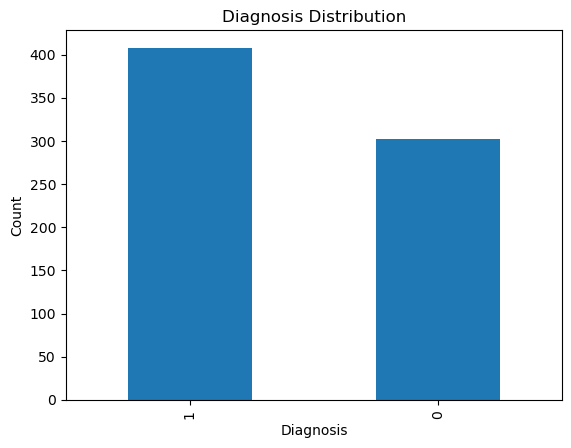

In [8]:
import matplotlib.pyplot as plt

df['Diagnosis'].value_counts().plot(kind='bar')

plt.title('Diagnosis Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')

plt.show()

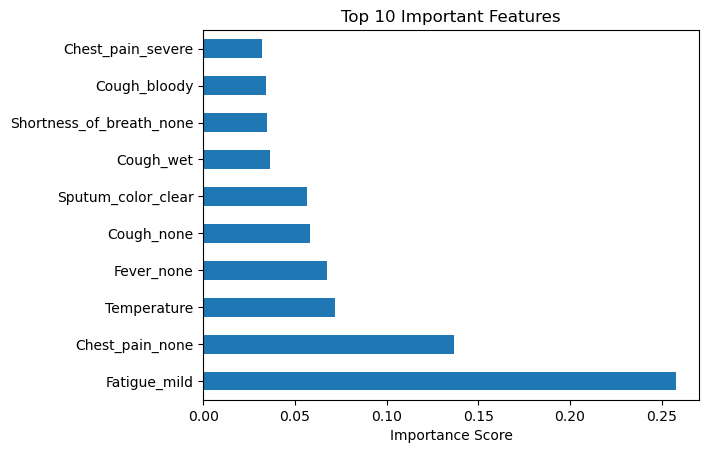

In [9]:
importance = pd.Series(
    Pneumonia_model.feature_importances_,
    index=X.columns
)

top_features = importance.sort_values(ascending=False).head(10)

top_features.plot(kind='barh')

plt.title('Top 10 Important Features')
plt.xlabel('Importance Score')

plt.show()

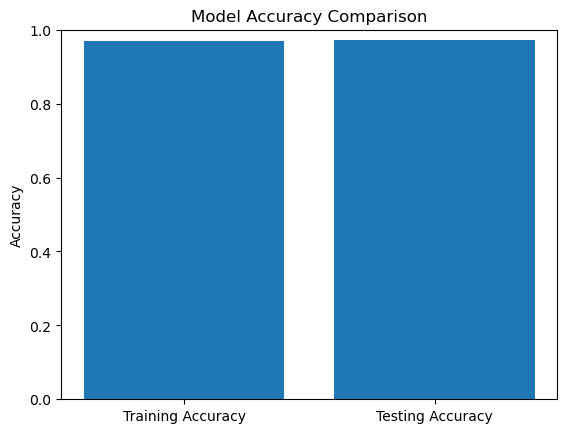

In [10]:
scores = [train_acc, test_acc]

labels = ['Training Accuracy', 'Testing Accuracy']

plt.bar(labels, scores)

plt.ylim(0,1)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')

plt.show()

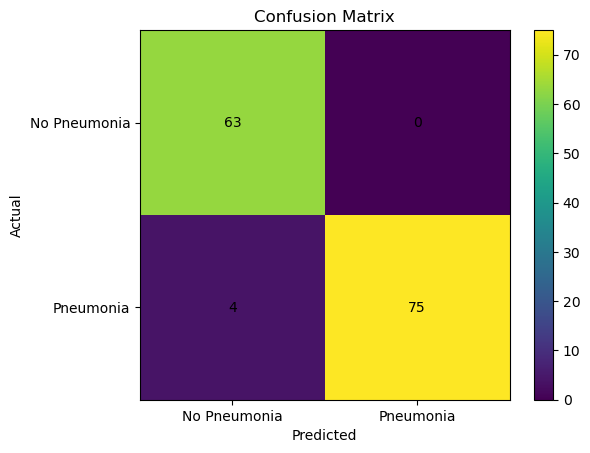

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, prediction)

plt.imshow(cm)

plt.title('Confusion Matrix')
plt.colorbar()

plt.xticks([0,1], ['No Pneumonia', 'Pneumonia'])
plt.yticks([0,1], ['No Pneumonia', 'Pneumonia'])

plt.xlabel('Predicted')
plt.ylabel('Actual')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

In [ ]:
df['Diagnosis'].value_counts().plot(kind='bar')

plt.title('Diagnosis Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')

plt.show()

C:\Users\Tariq\AppData\Local\Temp\ipykernel_15788\1775669380.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([no_pneumonia, pneumonia],


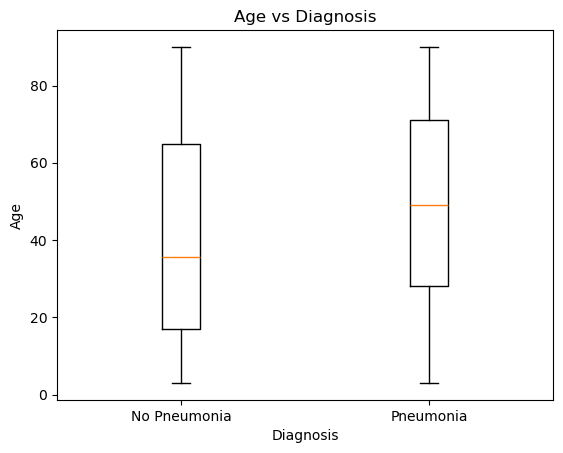

In [13]:

# Separate ages by diagnosis
no_pneumonia = df[df['Diagnosis'] == 0]['Age']
pneumonia = df[df['Diagnosis'] == 1]['Age']

# Create boxplot
plt.boxplot([no_pneumonia, pneumonia],
            labels=['No Pneumonia', 'Pneumonia'])

plt.title('Age vs Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Age')

plt.show()

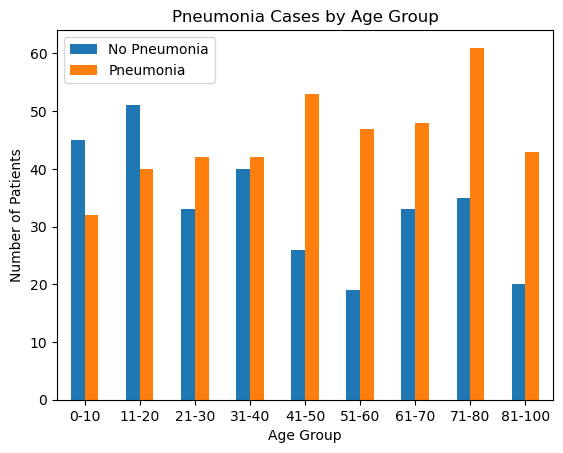

In [14]:
# Create age groups
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100]

labels = ['0-10', '11-20', '21-30', '31-40',
          '41-50', '51-60', '61-70', '71-80', '81-100']

df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Count pneumonia cases by age group
age_diag = pd.crosstab(df['Age_Group'], df['Diagnosis'])

# Create bar plot
age_diag.plot(kind='bar')

plt.title('Pneumonia Cases by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')

plt.xticks(rotation=0)
plt.legend(['No Pneumonia', 'Pneumonia'])

plt.show()